# A collaborative agent team designs alloys for AM printability

## Notes:
> - Access to Thermo-Calc, TC-python and OpenAI API key are needed.

#### Bo Ni, April 1, 2026


## 0. Check the floor

In [1]:
# # make into one block
# # 
# {
#     "tags": [
#         "hide-input",
#     ]
# }
# # 
#@CHech the base
import os, sys
print('Here is : \n', os.popen('pwd').read())
print('What we get in hardware: \n', os.popen('nvidia-smi').read())
kernel_name = os.path.basename(sys.executable.replace("/bin/python",""))
print ("The VirEnv kernal in action: ", kernel_name)
# 
# # make it work for both py and notebook
# try: 
#     from jupyter_client import kernelspec
#     spec = kernelspec.get_kernel_spec(kernel_name)
#     print("Path to it: ", spec.resource_dir)
# except:
#     print ("This suppose to be a .py run")
# # /path/to/my/kernel
try: 
    import torch
    print("What we have in software: \n Torch version:", torch.__version__) 
    print('Python: ', sys.version) # no switch case code
    # 
    print('What hardware the software see:')
    device = torch.device(
        "cuda:0" if torch.cuda.is_available() else "cpu"
    )
    print(device)
    num_of_gpus = torch.cuda.device_count()
    print("# of GPU", num_of_gpus)
    # 
    torch.cuda.empty_cache()
except:
    print ("No torch founded")
# 

Here is : 
 /trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_1/8_build_demos

What we get in hardware: 
 Thu Apr 16 01:05:46 2026       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 545.23.08              Driver Version: 545.23.08    CUDA Version: 12.3     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A40                     On  | 00000000:25:00.0 Off |                    0 |
|  0%   22C    P8              20W / 300W |      4MiB / 46068MiB |      0%      Default |
|                                     

In [2]:
# global setup
CKeys={}
CKeys['Debug']=1
CKeys['Test_TC']=0


In [3]:
# for TC-python 
# 
from dotenv import load_dotenv
load_dotenv('./local_safe/env_setup.custom')

True

In [4]:
# test
if CKeys['Debug']==1:
    print ( os.environ.get('LSHOST') )
    print ( os.environ.get('TC24A_HOME') )

172.24.116.37
/trace/group/tmousavi/software/Thermo-Calc/2024a


In [5]:
# a local test

if CKeys['Debug']==1 and CKeys['Test_TC']==1:
    import numpy as np
    from tc_python import *
    import matplotlib.pyplot as plt
    
    # list all the elments
    this_elem_list = ["Fe", "Cr", "C"]
    
    # CHOOSE database based on the elements
    this_database = "FEDEMO"
    
    # only specify the fraction of elements except the first element
    this_mole_frac_dict = {
        "Cr": 0.1,
        "C": 0.01,
    }
    
    # Step 2
    with TCPython(logging_policy=LoggingPolicy.NONE) as start:
        system = (
            start.
            select_database_and_elements(this_database, this_elem_list).
            get_system()
        )
        # Step 3
        scheil_calc = (
            system.
    		with_scheil_calculation().
            set_composition_unit(CompositionUnit.MOLE_FRACTION). # choose MOLE_FRACTION or MASS_FRACTION
            set_composition("Cr", this_mole_frac_dict["Cr"]).
            set_composition("C", this_mole_frac_dict["C"]).
    		calculate()
        )
        # Step 4
        # get all solid phase fraction at different T during solidification 
        mole_frac_all_solid, t_for_all_solid = scheil_calc.get_values_of(
            ScheilQuantity.mole_fraction_of_all_solid_phases(),
            ScheilQuantity.temperature()
        )
    
    # step 5
    fig, ax_1 = plt.subplots(1)
    ax_1.plot(
        np.array(mole_frac_all_solid), 
        np.array(t_for_all_solid) - 273.15, # convert T from Kelvin to Degree C
        label='All solid phases',
    )
    
    ax_1.set_xlabel("Mole fraction of all solid phases [-]")
    ax_1.set_ylabel("Temperature [\N{DEGREE SIGN} C]")
    ax_1.legend(loc="lower left")

## Working part

In [6]:
import autogen
# 
import chromadb
# Accepted file formats for that can be stored in
# a vector database instance
from autogen.retrieve_utils import TEXT_FORMATS
# agents:
from autogen import AssistantAgent
from autogen.agentchat.contrib.retrieve_user_proxy_agent import RetrieveUserProxyAgent
# coding environment
from autogen.coding import LocalCommandLineCodeExecutor
from typing import Annotated

# others:
import json
from IPython.display import Image

import shutil

In [7]:
config_file= "../Local_Store/Simple_OpenAI_Keys_Safe.json"


# for Agents

# config_list = autogen.config_list_from_json("OAI_CONFIG_LIST")

# ref:
# https://github.com/microsoft/autogen/blob/main/autogen/oai/openai_utils.py
config_list_agen = autogen.config_list_from_json(
    env_or_file=config_file, # "Simple_OpenAI_Keys_Safe.json",
    # file_location="../Local_Store/",
    filter_dict={
        "model": [
            "gpt-4o-2024-05-13",
            # "gpt-4o-2024-08-06",
            # "gpt-4o-mini",
        ],
    },
)

assert len(config_list_agen) > 0
print(
    "models to use: ", 
    [config_list_agen[i]["model"] for i in range(len(config_list_agen))]
)

models to use:  ['gpt-4o-2024-05-13']


### Local setup

In [8]:
wk_dir_base = "../Local_Store/For_8_3_2/"

if not os.path.exists(wk_dir_base):
    print (f"Create the base working path...")
    os.mkdir(wk_dir_base)

In [9]:
dir_list = os.listdir(wk_dir_base)

n_trial = len(dir_list)
wk_dir = wk_dir_base+'trial_'+str(n_trial)+'/'
print (wk_dir)

../Local_Store/For_8_3_2/trial_3/


In [10]:
# wk_dir = "../Local_Store/For_8_3_2/"

In [11]:
# # clean everything

# if CKeys['Debug']==1:
#     ## clean everything
#     if os.path.exists(wk_dir):
#         shutil.rmtree(wk_dir)
#         print (f"Remove everything...")

In [12]:
# file store

if not os.path.exists(wk_dir):
    print (f"Create working path...")
    os.mkdir(wk_dir)

Create working path...


In [13]:

# subdir
code_dir = wk_dir + "coding/"
vedb_dir = wk_dir + "vector_db/"

### Construct agents

In [14]:
def termination_msg(x):
    return isinstance(x, dict) and "TERMINATE" == str(x.get("content", ""))[-9:].upper()

In [15]:
# llm_config_agen = {
#     "config_list": config_list_agen, 
#     "timeout": 600, 
#     "temperature": 0.8, 
#     "seed": 1234
# }

llm_config_agen = {
    "config_list": config_list_agen, 
    "timeout": 1200, 
    "temperature": 0.8, 
    "seed": 1234
}

#### 1.

In [16]:
proxy_rag_retrieve_config = {
    "task": "code",
    "docs_path": [
        
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_01_Single_equilibrium_looping_and_3d_plotting.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_02_Single_equilibrium_solidus_and_liquidus_temperature.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_03_Scheil_mole_fraction_of_solid.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_04_Scheil_composition_distribution_Al_Si_Cu.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_05_Scheil_composition_profiles_Ni_base.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_06_Scheil_eutectic_fraction_Al_Si_Cu.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_07_Scheil_latent_heat_for_solidification_simulations.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_08_Property_diagram.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_09_Property_diagram_loop_parallel.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_10_Property_diagram_alloy_A_to_alloy_B.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_11_Phase_diagram.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_12_Phase_diagram_export_to_csv_file.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_13_Phase_diagram_single_phase_region_shift_Al_Si_Cu.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_14_Batch_equilibria.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_15_Scheil_back_diffusion.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_16_Scheil_Solute_Trapping_Al_Si_Cu.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_17_Material_to_Material_single_fraction_of_B.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_18_Material_to_Material_step_along_fraction_of_B.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_19_Material_to_Material_step_along_temperature.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_20_Material_to_Material_phase_diagram.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/database_info.md",
        
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_1/0_Example_Thermo_Calc.md",
        # "/trace/home/bni2/Thermo-Calc/2023b/SDK/TC-Python/Examples/Thermo-Calc/*py", # path to example.py files
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/Local_Store/For_0_6/TC_Python-2023.2.28684.30/tc_python/", # source code
        
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_0/0_code_tutorial_scheil_calculation.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_0/0_code_tutorial_single_equilibrium.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_0/1_supporting_info_2024.md", # for new TC
    ],
    "chunk_token_size": 1000, # 5000, # 1000,
    "model": config_list_agen[0]["model"], # config_list[0]["model"],
    # "vector_db": "chroma",
    "client": chromadb.PersistentClient(
        path=vedb_dir # "../Local_Store/tmp/chromadb"
    ),
    "overwrite": True,  # set to True if you want to overwrite an existing collection
    "get_or_create": False, # True, # False,  # set to False if don't want to reuse an existing collection
}
# 
proxy_rag_description_w_rag = """
A human admin. Interact with the planner to discuss the plan. Plan execution needs to be approved by this admin.
"""
# 
proxy_rag_description = """
A human admin. Interact with the planner to discuss the plan. Plan execution needs to be approved by this admin.
"""

In [17]:
# 
# option 1. Admin w/wo RAG
user_proxy_w_rag = RetrieveUserProxyAgent(
    name="Admin_w_RAG",
    # ++
    is_termination_msg=termination_msg,
    default_auto_reply="Reply `TERMINATE` if the task is done.",
    
    human_input_mode="NEVER",
    max_consecutive_auto_reply=10,
    # 
    retrieve_config=proxy_rag_retrieve_config,
    # 
    system_message=proxy_rag_description_w_rag,
    code_execution_config=False,
)

#### 2.

In [18]:
# coding configu

from types import SimpleNamespace

# Create a SimpleNamespace object with attributes
venv_SimNam = SimpleNamespace(
    env_dir="/trace/group/tmousavi/bni2/VirEnv/12_LLM_Modeling", 
    env_name="/trace/group/tmousavi/bni2/VirEnv/12_LLM_Modeling",
    bin_path="/trace/group/tmousavi/bni2/VirEnv/12_LLM_Modeling/bin/"
)

In [19]:

executor_code_exe_config = {
    # the executor to run the generated code
    # ++
    # "executor": jupyter.JupyterCodeExecutor()
    # -- it's shell, no environment is activated
    "executor": LocalCommandLineCodeExecutor(
        # virtual_env_context="/trace/home/bni2/Group_WSpace_250GB/group_folder/bni2/VirEnv/6_LLM_Modelling",
        # ++
        virtual_env_context= venv_SimNam,
        work_dir= code_dir, # wk_dir + "coding"
        # ++
        timeout=6000,
    ),
}  # set to False if you don't want to execute the code

In [20]:
# 2. planner
planner = autogen.AssistantAgent(
    name="Planner",
    system_message="""\
Planner. Suggest a plan. 
Revise the plan based on feedback from admin and critic, until admin approval.
The plan may involve 
a scientist who is expert in material science and formulating computational materials science problem but doesn't write code,
and 
an engineer who can write python code using Themo-calc via TC_pyhton.
Explain the plan first. 
Be clear which step is performed by an engineer, and which step is performed by a scientist.
""",
    llm_config=llm_config_agen,
    # ++
    is_termination_msg=termination_msg,
)

# 3. scientist
scientist = autogen.AssistantAgent(
    name="Scientist",
    llm_config=llm_config_agen,
    system_message="""\
Material scientist. You follow an approved plan. 
You don't write code.
You are able to use material science knowledge to formulate computational thermodynamics problem with clear material composition for the engineer to write code to solve.
You pay attention to distinguish single equlibrium and Scheil calculaitons based on solidification process indicated by the problem statement.
""",
    # ++
    is_termination_msg=termination_msg,
)

# 4. engineer
engineer = autogen.AssistantAgent(
    name="Engineer",
    llm_config=llm_config_agen,
    system_message='''\
Engineer. You follow an approved plan. 
You write python/shell code to solve tasks in computational material science, especially CALPHAD. 
Based on the provided examples and information, you write python script to run Themro-Calc via tc_python to do calculations.

Wrap the code in a code block that specifies the script type. 
The user can't modify your code. So do not suggest incomplete code which requires others to modify. Don't use a code block if it's not intended to be executed by the executor.
Don't include multiple code blocks in one response. Do not ask others to copy and paste the result. Check the execution result returned by the executor.
If the result indicates there is an error, fix the error and output the code again. Suggest the full code instead of partial code or code changes. If the error can't be fixed or if the task is not solved even after the code is executed successfully, analyze the problem, revisit your assumption, collect additional info you need, and think of a different approach to try.
In the code you write, always save the results in terms of json and png files for the Scientist to check.
''',
    # ++
    is_termination_msg=termination_msg,
)

# 5. executor
executor = autogen.UserProxyAgent(
    name="Executor",
    system_message="""\
Executor. Execute the code written by the engineer and report the result.
""",
    human_input_mode="NEVER",
    # # --
    # code_execution_config={
    #     "last_n_messages": 3,
    #     "work_dir": code_dir,
    #     "use_docker": False,
    # },  # Please set use_docker=True if docker is available to run the generated code. Using docker is safer than running the generated code directly.
    # ++
    # code_execution_config={
    #     # the executor to run the generated code
    #     # ++
    #     # "executor": jupyter.JupyterCodeExecutor()
    #     # -- it's shell, no environment is activated
    #     "executor": LocalCommandLineCodeExecutor(
    #         # virtual_env_context="/trace/home/bni2/Group_WSpace_250GB/group_folder/bni2/VirEnv/6_LLM_Modelling",
    #         work_dir= wk_dir + "coding",
    #         timeout=6000,  # Timeout for each code execution in seconds.
    #     ),
    # },  # set to False if you don't want to execute the code
    # +++
    code_execution_config=executor_code_exe_config,

    # ++
    # is_termination_msg=termination_msg,
)

# 6. Critic
critic = autogen.AssistantAgent(
    name="Critic",
    system_message="""\
Critic. Double check plan, claims, code from other agents, results and provide feedback. 
Check whether the plan includes adding verifiable info such as source URL.
""",
    llm_config=llm_config_agen,
    # ++
    is_termination_msg=termination_msg,
)

In [21]:
def _reset_agents():
    user_proxy_w_rag.reset()
    planner.reset()
    scientist.reset()
    engineer.reset()
    executor.reset()
    critic.reset()

In [22]:
groupchat = autogen.GroupChat(
    agents=[
        user_proxy_w_rag, engineer, scientist, 
        planner, executor, critic
    ], 
    messages=[], 
    max_round=50
)
manager = autogen.GroupChatManager(
    groupchat=groupchat, 
    llm_config=llm_config_agen
)

### start the chat

In [23]:
_reset_agents()

In [24]:
Task_stat_3 = """\
Let's design Al-Si alloy composition that is optimized for good printability for additive manufacturing.
Please find the suitable compositions and save the results and key evidence in a json file and png file.
"""

In [25]:
chat_resu_w_RAG = user_proxy_w_rag.initiate_chat(
    manager,
    message=user_proxy_w_rag.message_generator,
    problem=Task_stat_3
)

Trying to create collection.


2026-04-16 01:06:08,836 - autogen.agentchat.contrib.retrieve_user_proxy_agent - INFO - Found 3 chunks.
2026-04-16 01:06:08,890 - autogen.agentchat.contrib.vectordb.chromadb - INFO - No content embedding is provided. Will use the VectorDB's embedding function to generate the content embedding.
Number of requested results 20 is greater than number of elements in index 3, updating n_results = 3


VectorDB returns doc_ids:  [['c909cfd3', '2828a2dd', '5c9f6a8b']]
Adding content of doc c909cfd3 to context.
Adding content of doc 2828a2dd to context.
Adding content of doc 5c9f6a8b to context.
Admin_w_RAG (to chat_manager):

You're a retrieve augmented coding assistant. You answer user's questions based on your own knowledge and the
context provided by the user.
If you can't answer the question with or without the current context, you should reply exactly `UPDATE CONTEXT`.
For code generation, you must obey the following rules:
Rule 1. You MUST NOT install any packages because all the packages needed are already installed.
Rule 2. You must follow the formats below to write your code:
```language
# your code
```

User's question is: Let's design Al-Si alloy composition that is optimized for good printability for additive manufacturing.
Please find the suitable compositions and save the results and key evidence in a json file and png file.


Context is: 1. Thermo-calc 2024a and TC-pyth

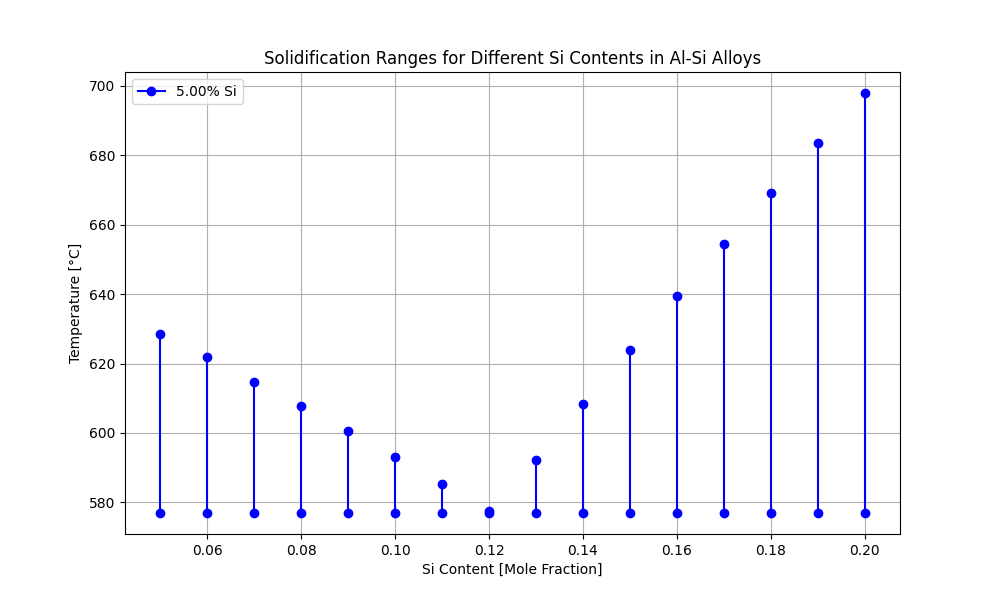

In [26]:
# al_si_scheil_plot.png
Image(code_dir+'solidification_ranges.png')

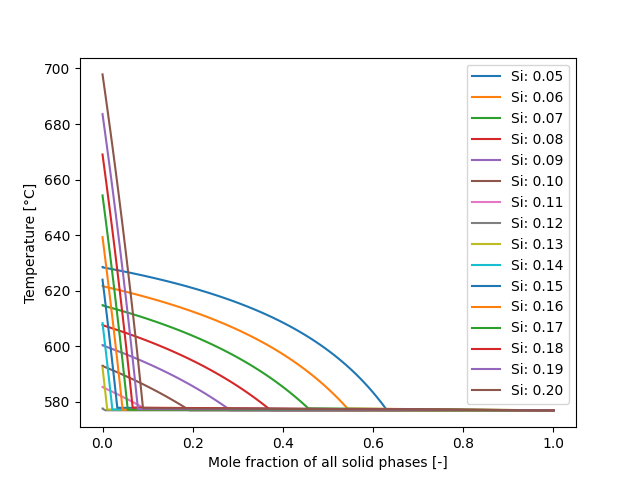

In [27]:
Image(code_dir+'solidification_behavior.png')

In [28]:
Task_stat_3_2 = """\
Good. 
Now, among those with good printability, let's select one of the highest strength.
Please save your result in a json file and png file.
"""

In [29]:
user_proxy_w_rag.send(
    recipient=manager,
    message=Task_stat_3_2,
)

Admin_w_RAG (to chat_manager):

Good. 
Now, among those with good printability, let's select one of the highest strength.
Please save your result in a json file and png file.


--------------------------------------------------------------------------------

Next speaker: Engineer

Engineer (to chat_manager):

### Plan to Select the Highest Strength Al-Si Alloy Composition

The goal is to identify the Al-Si alloy composition with the highest strength among those with good printability (Si compositions between 6.00% and 15.00%). To achieve this, we will follow these steps:

### Step-by-Step Plan

#### Step 1: Define Strength Criteria (Material Scientist)
- **Task:** Define criteria to estimate or calculate the strength of the alloy compositions.
- **Details:** 
  - Utilize available thermodynamic data, phase fractions, and other relevant properties.
  - Consider additional sources or empirical models if necessary.

#### Step 2: Setup Calculations for Strength Estimation (Engineer)
- **T

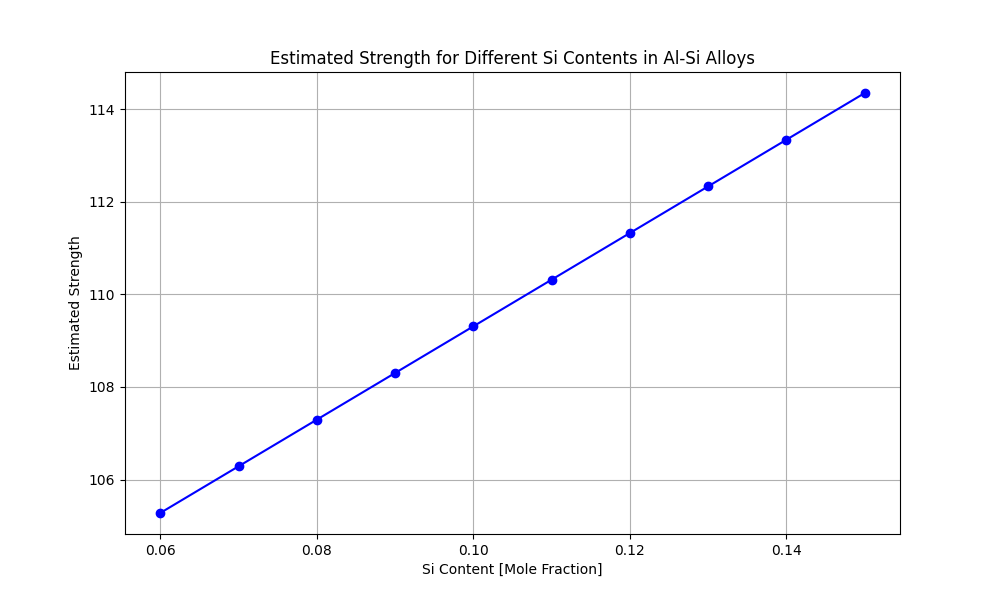

In [30]:
Image(code_dir+'strength_vs_si_content.png')

In [27]:
with open(code_dir+'/alloy_results.json') as f:
    d = json.load(f)
print (d)

[{'composition': {'Si': 0.02}, 'solidification_history': {'mole_frac_all_solid': [0.0, 0.0, 0.0004981271472365688, 0.08234402358748823, 0.1521674797223081, 0.21240140389613785, 0.2648679005588232, 0.31095794174336744, 0.35175128667326916, 0.38809857863387204, 0.4206788190371062, 0.4500404099600714, 0.4766309871809174, 0.5008194537694736, 0.5229124895874215, 0.5431670847546732, 0.5618001690759216, 0.5789960917980467, 0.5949124904315829, 0.609684938614206, 0.6234306588583306, 0.6362515121272707, 0.6482364230862352, 0.6594633612682547, 0.670000970024426, 0.679909914062262, 0.6892440005875824, 0.6980511171260061, 0.7063740199950669, 0.7142510003999893, 0.7217164497074143, 0.72880134122542, 0.7355336425020783, 0.7419386695334411, 0.7480393921904352, 0.7538566985098129, 0.7594096241568806, 0.7647155522880109, 0.7697903881643315, 0.7746487121529143, 0.7793039141665264, 0.7837683121111806, 0.7880532565128101, 0.7921692231644353, 0.7961258953605909, 0.799932237056131, 0.8035965580942465, 0.8071

### Save the chat history

In [29]:
print (
    f"Current Len of the chat history: {len(chat_resu_w_RAG.chat_history)}"
)

Current Len of the chat history: 12


In [30]:
# save the chat
import pickle

save_chat_hist = wk_dir + './chat_hist_from_0.pk'

if not os.path.exists(save_chat_hist):
    # writing in binary mode
    with open(save_chat_hist, 'wb') as out_handle:
        pickle.dump(chat_resu_w_RAG, out_handle, pickle.HIGHEST_PROTOCOL)